# E237 — Causal cross-regime transfer

**complete** · All paired continuations and both gate tests complete

**240/240** continuations · **68/68** cached raw clips

Updated 2026-11-23T14:31:31+01:00 Stockholm time. Estimated finish **—**.

This experiment tests whether sharing an AdamW update between A and B improves B semantics compared with using the same exposures in pure batches. The strongest ordered control determines the mechanistic contrast. At a fixed model state MAE averages the per-image gradients. The protocols can therefore differ through gradient grouping, moment updates and the subsequent optimization path. A positive result would identify a benefit of the mixed optimization protocol in this setting.

Prior work compares merged and separate replay updates in supervised continual learning. E237 tests semantic transfer under label-free buffered MAE adaptation with exactly matched exposure counts and optimizer steps. [Krutsylo, Continual Learning with Experience Replay, §5.1](https://ipipan.waw.pl/pliki/doktoraty/Krutsylo/Krutsylo_Doktorat.pdf).

Every walk trains on initial A and then B for 192 updates each. All continuation arms restore the same post-B weights and AdamW state. The returning-A clip is already buffered when the branch starts, and historical memory draws from the observed first-A or first-B clip. Each continuation uses 192 updates, two images per update, and the E235 learning rate of 7.5e-5. The four source-matched arms consume the exact same exposures in different batches. The historical banks each hold 64 images. Pixel transforms are identity as in E235. In each of 4 independent draws, an exposure carries the same MAE mask and visible-token order wherever that exposure appears.

Joint replay uses 96 AB and 96 AA batches. The interleaved control uses one BB batch per four updates, giving the same cumulative A and B counts as joint replay at all three readouts. The A-then-B and B-then-A controls reach matched counts at the 192-update endpoint.

Fresh raw captures construct ten disjoint A→B→A walks and separate raw A/B holdouts. Those holdouts anchor distinct annotated A/B panels per walk. The primary score is the mean balanced accuracy of scene, weather, traffic light, pedestrian. Lighting and scene kNN are diagnostics. The primary panel has at least 30 examples per class. The label-blind split ranks evaluation clips using frozen embeddings and assigns A/B without class information. Evaluation labels enter the probes and reported statistics. Confidence intervals cluster by walk and condition on the shared annotated corpus.

Gate A at 192 updates requires a **+0.25 pp** or larger B advantage over the best source-matched pure-batch control and a positive interval. Gate B selects the highest B endpoint among the six policies. It requires **+0.25 pp** or more B acquisition relative to pre-B and a lower interval above zero. The simultaneous lower interval for A must also clear **−0.25 pp** versus pre-B.


| Continuation | Incoming A | Historical B | Historical A | Repeated incoming A |
| --- | --- | --- | --- | --- |
| Joint A+B replay | 288 | 96 | 0 | 0 |
| Interleaved pure batches | 288 | 96 | 0 | 0 |
| A then B | 288 | 96 | 0 | 0 |
| B then A | 288 | 96 | 0 | 0 |
| A + historical A | 288 | 0 | 96 | 0 |
| A-only matched repetition | 288 | 0 | 0 | 96 |

| Walk | A/B cosine distance | Min primary class support | Min label-blind primary class support |
| --- | --- | --- | --- |
| 1 | 0.088 | 35 | 28 |
| 2 | 0.115 | 35 | 27 |
| 3 | 0.511 | 35 | 25 |
| 4 | 0.506 | 35 | 26 |
| 5 | 0.101 | 35 | 27 |
| 6 | 0.128 | 35 | 24 |
| 7 | 0.115 | 35 | 26 |
| 8 | 0.464 | 35 | 25 |
| 9 | 0.441 | 35 | 25 |
| 10 | 0.385 | 35 | 25 |

## Decision gates

**Gate A missed.** Joint A+B versus **Interleaved pure batches** at 192 updates was **+0.025 [-0.156, +0.054] pp** on B. Label-blind joint versus its strongest control (Interleaved pure batches) was **+0.013 [-0.269, +0.037] pp**.

**Gate B missed.** The highest B endpoint was **Joint A+B replay**. Its net acquisition over pre-B was **+0.504 [-0.142, +1.149] pp** on B and **+0.450 [-0.195, +1.096] pp** on A, with simultaneous 95% intervals over policies and sides.

Initial B training changed B by **+0.012 [-0.155, +0.177] pp** and A by **+0.542 [+0.191, +0.930] pp**.


| Policy | A vs post-B (pp) | B vs post-B (pp) | A vs pre-B (pp) | B vs pre-B (pp) | Label-blind B vs pre-B (pp) | Training (s) |
| --- | --- | --- | --- | --- | --- | --- |
| Joint A+B replay | -0.092 [-0.782, +0.612] | +0.492 [+0.101, +0.879] | +0.450 [-0.174, +1.058] | +0.504 [+0.170, +0.808] | +0.512 [+0.217, +0.765] | 1.85 |
| Interleaved pure batches | -0.118 [-0.802, +0.582] | +0.467 [+0.076, +0.856] | +0.424 [-0.183, +1.017] | +0.479 [+0.133, +0.794] | +0.499 [+0.207, +0.749] | 1.84 |
| A then B | -0.054 [-0.411, +0.296] | +0.237 [-0.054, +0.526] | +0.489 [+0.008, +0.987] | +0.250 [+0.050, +0.456] | +0.491 [+0.250, +0.730] | 1.84 |
| B then A | -0.149 [-0.580, +0.278] | -0.077 [-0.336, +0.152] | +0.393 [-0.085, +0.870] | -0.065 [-0.253, +0.135] | +0.201 [-0.059, +0.432] | 1.84 |
| A + historical A | -0.109 [-0.555, +0.347] | +0.255 [-0.039, +0.571] | +0.433 [-0.080, +0.938] | +0.267 [-0.063, +0.559] | +0.358 [+0.062, +0.638] | 1.84 |
| A-only matched repetition | -0.367 [-0.788, +0.081] | -0.035 [-0.280, +0.216] | +0.175 [-0.284, +0.640] | -0.023 [-0.277, +0.208] | +0.243 [-0.003, +0.431] | 1.84 |

| B advantage of Joint A+B | 48 updates (pp) | 96 updates (pp) | 192 updates (pp) | 192 updates, label-blind (pp) |
| --- | --- | --- | --- | --- |
| Interleaved pure batches | +0.002 [-0.018, +0.025] | +0.016 [-0.009, +0.042] | +0.025 [-0.006, +0.056] | +0.013 [-0.018, +0.047] |
| A then B | +0.260 [+0.019, +0.528] | +0.336 [+0.038, +0.638] | +0.254 [-0.156, +0.634] | +0.022 [-0.269, +0.264] |
| B then A | +0.064 [-0.300, +0.426] | +0.275 [+0.021, +0.537] | +0.569 [+0.148, +0.906] | +0.311 [+0.012, +0.556] |
| A + historical A | +0.163 [-0.129, +0.439] | +0.276 [+0.012, +0.533] | +0.237 [-0.295, +0.731] | +0.154 [-0.263, +0.510] |
| A-only matched repetition | +0.217 [-0.082, +0.503] | +0.403 [+0.109, +0.699] | +0.527 [+0.090, +0.877] | +0.269 [-0.006, +0.477] |

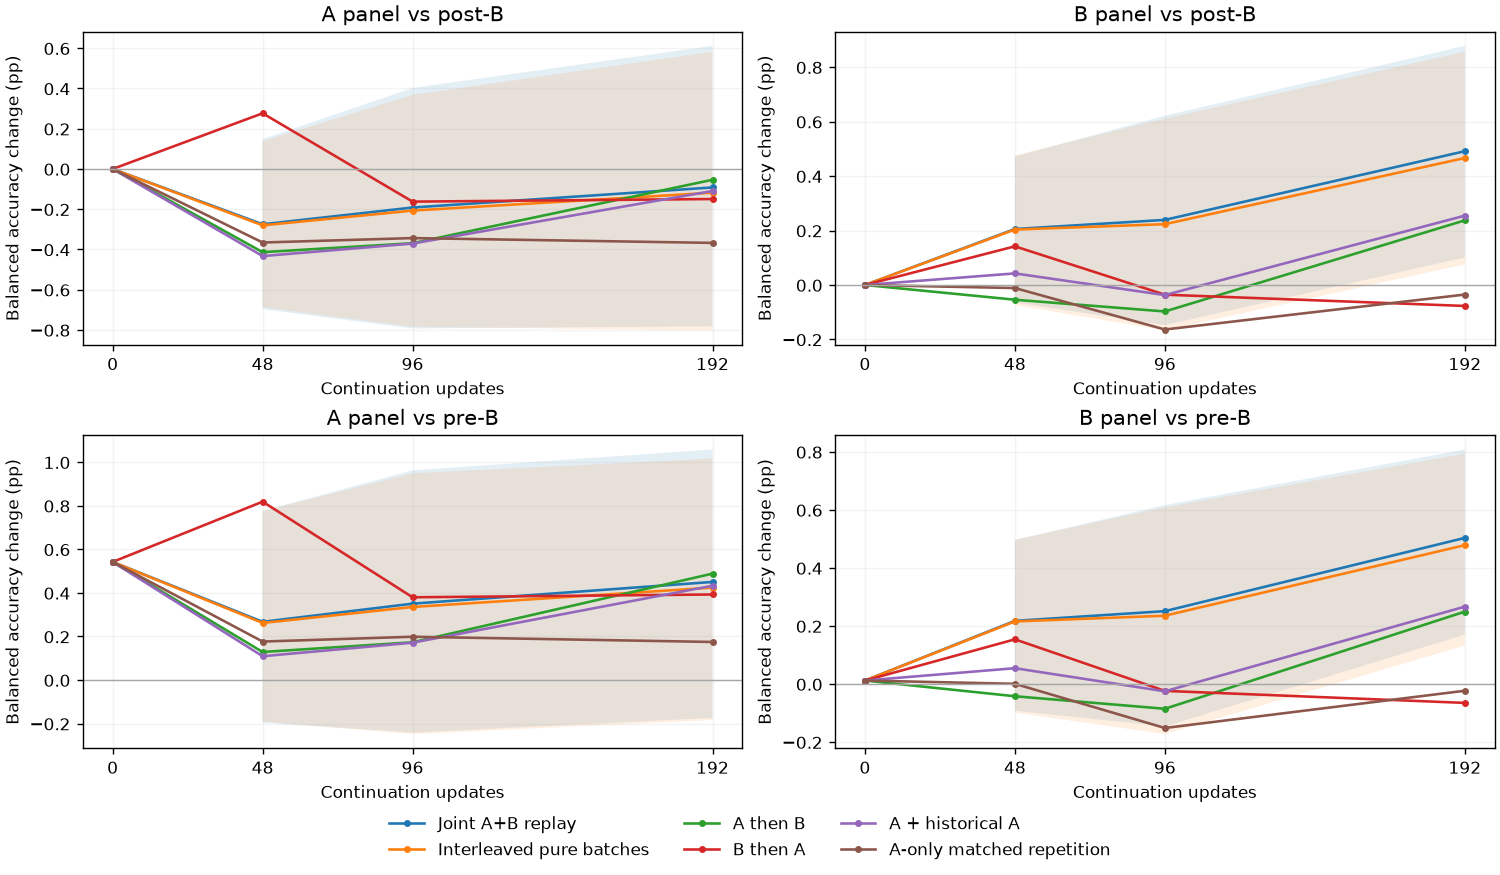

| A tasks vs pre-B after 192 updates (pp) | scene | weather | traffic light | pedestrian | lighting | scene kNN |
| --- | --- | --- | --- | --- | --- | --- |
| Joint A+B replay | +0.586 [-0.147, +1.454] | +1.056 [-0.435, +3.008] | -0.414 [-0.872, +0.047] | +0.575 [-0.527, +1.545] | -0.170 [-0.308, -0.053] | -0.231 [-1.430, +1.059] |
| Interleaved pure batches | +0.522 [-0.195, +1.336] | +1.035 [-0.471, +2.943] | -0.415 [-0.843, +0.007] | +0.555 [-0.545, +1.539] | -0.161 [-0.297, -0.046] | -0.322 [-1.402, +0.855] |
| A then B | +0.314 [-0.377, +1.033] | +0.653 [-0.507, +2.013] | -0.239 [-0.914, +0.321] | +1.226 [+0.404, +2.131] | -0.033 [-0.106, +0.032] | -0.318 [-1.523, +0.625] |
| B then A | +0.050 [-0.934, +1.060] | +0.674 [-0.821, +2.463] | -0.166 [-0.742, +0.310] | +1.014 [+0.201, +1.904] | -0.001 [-0.081, +0.070] | -0.811 [-2.114, +0.544] |
| A + historical A | +0.331 [-0.561, +1.241] | +0.401 [-0.903, +1.943] | -0.609 [-1.040, -0.209] | +1.609 [+0.901, +2.319] | -0.063 [-0.143, +0.024] | -0.580 [-1.693, +0.638] |
| A-only matched repetition | -0.206 [-1.105, +0.642] | +0.319 [-0.965, +2.071] | -0.270 [-0.826, +0.213] | +0.856 [-0.100, +1.874] | +0.014 [-0.068, +0.086] | -0.618 [-1.803, +0.569] |

| B tasks vs pre-B after 192 updates (pp) | scene | weather | traffic light | pedestrian | lighting | scene kNN |
| --- | --- | --- | --- | --- | --- | --- |
| Joint A+B replay | +0.342 [-0.508, +1.274] | +1.851 [+0.442, +3.292] | -0.184 [-0.755, +0.433] | +0.006 [-0.470, +0.537] | -0.005 [-0.277, +0.258] | +0.738 [-0.001, +1.459] |
| Interleaved pure batches | +0.285 [-0.578, +1.222] | +1.809 [+0.401, +3.247] | -0.166 [-0.749, +0.473] | -0.014 [-0.501, +0.519] | -0.005 [-0.258, +0.249] | +0.685 [-0.089, +1.431] |
| A then B | +1.159 [+0.571, +1.769] | +0.651 [-0.495, +1.758] | -0.026 [-0.598, +0.572] | -0.786 [-1.263, -0.277] | +0.286 [-0.078, +0.673] | +0.635 [+0.165, +1.155] |
| B then A | -0.248 [-1.175, +0.647] | +0.699 [-0.485, +1.800] | -0.080 [-0.713, +0.577] | -0.630 [-1.317, +0.153] | -0.116 [-0.527, +0.341] | +0.752 [-0.231, +1.716] |
| A + historical A | +0.236 [-0.600, +1.056] | +0.994 [+0.050, +2.050] | +0.086 [-0.309, +0.530] | -0.249 [-0.724, +0.275] | -0.023 [-0.342, +0.309] | +0.832 [+0.109, +1.419] |
| A-only matched repetition | -0.531 [-1.516, +0.446] | +1.187 [-0.117, +2.367] | -0.157 [-0.679, +0.412] | -0.592 [-1.181, +0.033] | -0.176 [-0.550, +0.235] | +0.668 [-0.214, +1.433] |